In [102]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor  
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error 
from sklearn.model_selection import train_test_split
from scipy.special import expit,softmax # expit : 이진 분류함수 softmax : 다중분류


In [103]:
fish = pd.read_csv('data/fish_logistic.csv')

In [104]:
fish['Species'].unique() # 7개 종류 :'Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt'

<StringArray>
['Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt']
Length: 7, dtype: str

In [105]:
# 데이터 전처리 
data = fish[fish.columns[1:]].values
label = fish['Species'].values


In [106]:
# 데이터 분리
train_data, test_data, train_label, test_label = train_test_split(data,label,random_state=42)


In [107]:
# logisticRegression 정규화 작업을 꼭 해야함

ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data) 

In [108]:
# 다중 분류 
# C (대문자 표시, 매개변수) - alpha, C : 규제, C가 높아지면 완화, 낮아지면 강화
# alpha 는 for 문 그래프ㅗㄹ 가장 최적화된 규제를 찾아서 적용
# max_iter 는 반복을 자동화해주는 매개변수

lr = LogisticRegression(C=20,max_iter=1000) # C는 defult 값이 20, 1000번 반복한다는 의미
lr.fit(train_scaled,train_label)
print()


In [109]:
lr.classes_ # 확률이 어떤 것인지 확인하는 작업 

# z 함수에 expit (로지스틱 함수) 로 실행

array(['Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish'],
      dtype=object)

In [110]:
predict = lr.predict_proba(test_scaled[:5])
decisions = lr.decision_function(test_scaled[:5])

# 음수값을 양수값으로 변경 
soft1 = softmax(decisions,axis=1) # axis=1 : 행방향으로 출력 / axis=0 : 열방향으로 출력
np.round(soft1,decimals=3)



array([[0.   , 0.014, 0.842, 0.   , 0.135, 0.007, 0.003],
       [0.   , 0.003, 0.044, 0.   , 0.007, 0.946, 0.   ],
       [0.   , 0.   , 0.034, 0.934, 0.015, 0.016, 0.   ],
       [0.011, 0.034, 0.305, 0.006, 0.567, 0.   , 0.076],
       [0.   , 0.   , 0.904, 0.002, 0.089, 0.002, 0.001]])

In [111]:
print('train 정확도:', lr.score(train_scaled,train_label))
print('test 정확도:', lr.score(test_scaled,test_label))

train 정확도: 0.9327731092436975
test 정확도: 0.925


In [112]:
fish[:2]

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.0200
1,Bream,290.0,26.3,31.2,12.48,4.3056


In [113]:
# 무게, 길이, 대각선, 높이, 넓이를 입력받아 
# 분류생선과 확률을 출력하시오. 
# 분류 생선은 93.1% 확률로 Bream 펀별됩니다.... 이런 식으로 출력하시오. 
# 242.0	25.4	30.0	11.52	4.020
# 290.0	26.3	31.2	12.48	4.3056
train_data[:5]

array([[720.    ,  35.    ,  40.6   ,  16.3618,   6.09  ],
       [500.    ,  45.    ,  48.    ,   6.96  ,   4.896 ],
       [  7.5   ,  10.5   ,  11.6   ,   1.972 ,   1.16  ],
       [110.    ,  22.    ,  23.5   ,   5.5225,   3.995 ],
       [140.    ,  20.7   ,  23.2   ,   8.5376,   3.2944]])

In [114]:
ss = StandardScaler()
ss.fit(train_data,train_label)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [115]:
# in_data = input('생선의 무게, 길이, 대각선, 높이, 넓이를 입력하세요. 예)242.0	25.4	30.0	11.52	4.020 ')
# in_data = in_data.split('\t')
# in_data = list(map(float,in_data))
# in_data

# in_data = input('생선의 무게, 길이, 대각선, 높이, 넓이를 입력하세요. >> 예)242.0	25.4	30.0	11.52	4.020')
in_data = '300,35,38.8,5.9364,4.3844' # Pike 0.00%
# in_data = '242.0,25.4,30.0,11.52,4.0200' # Bream 58.06%
# in_data = '55,14.7,16.5,6.8475,2.3265' # Parkki 95.72% 
# in_data = '32,13.7,14.7,3.528,1.9992' # Perch 3.17%
in_data = in_data.split(',') # 콤마로 분리할지 \t로 분리할지는 일단 실행해본 후 이상이 있을 경우 변경하면 됨
in_data = list(map(float, in_data))
in_data



[300.0, 35.0, 38.8, 5.9364, 4.3844]

In [116]:
in_data_scaled = ss.transform([in_data])
proba = lr.predict_proba(in_data_scaled)

result = lr.predict(in_data_scaled)
result2 = lr.predict_proba(in_data_scaled)
print(lr.predict_proba(in_data_scaled))
if result[0] == "Bream":
    result3 = result2[0][0]
elif result[0] == "Parkki":
    result3 = result2[0][1]
elif result[0] == "Perch":
    result3 = result2[0][2]  
elif result[0] == "Pike":
    result3 = result2[0][3]    
elif result[0] == "Roach":
    result3 = result2[0][4]   
elif result[0] == "Smelt":
    result3 = result2[0][5]
else :
    result3 = result2[0][6]
print(result3)
print(f'분류생선 : ({result3*100:.2f})%의 확률로 {result} 판별합니다.')

[[9.62321049e-06 1.07028103e-07 6.23057970e-02 9.20347539e-01
  1.68175044e-02 4.50072165e-04 6.93569585e-05]]
0.9203475392290786
분류생선 : (92.03)%의 확률로 ['Pike'] 판별합니다.


In [120]:
# 다중 분류 
# C (대문자 표시, 매개변수) - alpha, C : 규제, C가 높아지면 완화, 낮아지면 강화
# alpha 는 for 문 그래프ㅗㄹ 가장 최적화된 규제를 찾아서 적용
# max_iter 는 반복을 자동화해주는 매개변수

train_score = []
test_score = []
cc = [0.001,0.01,0.1,1,10,20,50,100]
for c in cc:
    lr = LogisticRegression(C=c,max_iter=1000) # C는 defult 값이 20, 1000번 반복한다는 의미
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled,train_label))
    test_score.append(lr.score(test_scaled,test_label))
    print()


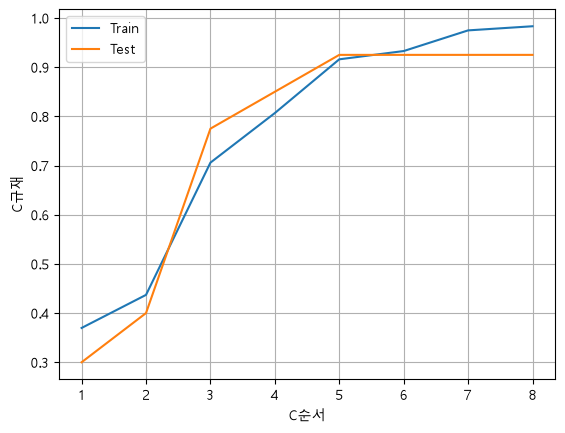

In [125]:
# C의 규제 선 그래프 
list1 = [1,2,3,4,5,6,7,8]
plt.plot(list1,train_score)
plt.plot(list1,test_score)
plt.grid()
plt.legend(['Train','Test'])
plt.xlabel('C순서')
plt.ylabel('C규재')
plt.show()
